# LPC Vocoder
This project implements a Linear Predictive Coding compression scheme. You are given 10 audio 
samples to evaluate your system, and your goal is: 
(a)  Compress the signals into as few coefficients as you can so that it can be transmitted 
over a communication channel. Your transmitter will estimate the prediction parameters 
𝑎! and gain 𝐺 for each signal on a frame-by-frame basis.  
(b)  Using  the  parameters  {𝑎!,𝐺},  re-synthesize  the  original  sentence  with  the  highest 
possible quality.  
The ultimate goal is a reconstructed waveform with the best possible quality, using the least 
number  of  coefficients.  Your  report  MUST  include  an  estimate  of  the  average  number  of 
parameters in bits/second or samples/second.

In [1]:
import numpy as np
import soundfile as sf

# loading in data
data = []
for i in range(1, 11):
    rec, fs = sf.read(f'Project4_LPC_Audio/Sample{i}.wav')
    rec = rec/np.max(np.abs(rec))
    f0 = np.loadtxt(f'Project4_LPC_Voicing/sample{i}.txt')
    print(fs, f0.shape)
    data.append({'idx': f'{i}', 'rec': rec, 'fs': fs, 'f0': f0})

16000 (167,)
16000 (169,)
16000 (192,)
16000 (184,)
16000 (187,)
16000 (194,)
16000 (158,)
16000 (189,)
16000 (133,)
16000 (178,)


# figuring out lpc

order 1: err = 0.013361714757392368
order 2: err = 0.0008551074620722496
order 3: err = 0.000743086264915543
order 4: err = 0.0007043308376678262
order 5: err = 0.0006845647439292543
order 6: err = 0.000678477212819856
order 7: err = 0.0006742553256261331
order 8: err = 0.000671613647451242
order 9: err = 0.0006716130213626511
order 10: err = 0.0006352653904630066
order 11: err = 0.0006338164394272155
order 12: err = 0.0006288824259821654
order 13: err = 0.0006288190516993071
order 14: err = 0.0006288179371041875
order 15: err = 0.0006268621274319244
order 16: err = 0.0006077358209723955
[ 1.         -1.45136482  0.26537302  0.02418545  0.03342998  0.01393011
  0.19355011  0.08839964  0.01085666 -0.34252148  0.14589673 -0.08102797
  0.06437339 -0.01153295  0.03393253  0.19944803 -0.17467451]


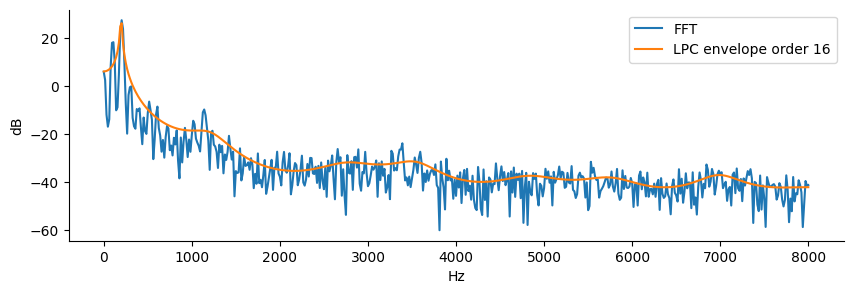

In [2]:
# SAMPLE TEST

x = data[0]['rec']
fs = data[0]['fs']
N = int(0.05*fs)
start = len(x)//2-N//2 
frame = x[start:start+N]*np.hamming(N)
# for testing i'm just using a random 30ms interval of first file

autocorr = np.array([np.dot(frame[:N-lag], frame[lag:]) for lag in range(17)])
autocorr[0] *= 1.0000001

# levinson durbin
lpc_coeffs = np.zeros(17)
lpc_coeffs[0] = 1.0
pred_err = autocorr[0]  # order 0 (frame energy)
for i in range(1, 17):
    # how much order i improves on order i-1
    _0_coeff = -(autocorr[i]+np.dot(lpc_coeffs[1:i], autocorr[i-1:0:-1]))/pred_err

    lpc_coeffs[1:i] = lpc_coeffs[1:i]+_0_coeff*lpc_coeffs[i-1:0:-1]
    lpc_coeffs[i] = _0_coeff

    pred_err = pred_err*(1-_0_coeff**2)
    print(f'order {i}: err = {pred_err}')
print(lpc_coeffs)

# LPC envelope on actual spectrum
# sps.freqz(np.sqrt(pred_err), lpc_coeffs, 512, fs=fs)
# i'm rewriting this here (acc to freqz docs) since not sure if we're allowed to use it
# but basically just getting freq response of the filter defined by the lpc coefficients
h = np.sqrt(pred_err)/np.fft.rfft(lpc_coeffs, 1024)
w = np.fft.rfftfreq(1024, 1/fs)
spec = 20*np.log10(np.abs(np.fft.rfft(frame, 1024))+0.000000001)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
plt.plot(np.fft.rfftfreq(1024, 1/fs), spec, label='FFT')
plt.plot(w, 20*np.log10(np.abs(h)), label='LPC envelope order 16')
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.xlabel('Hz');
plt.ylabel('dB');
plt.legend()
plt.show()

In [3]:
# lpc code (reconfiguring lol)

def lpc(frame, order):
    autocorr = np.array([np.dot(frame[:len(frame)-lag], frame[lag:]) for lag in range(order+1)])
    autocorr[0] *= 1.0001
    
    lpc_coeffs = np.zeros(order+1)
    lpc_coeffs[0] = 1.0
    pred_err = autocorr[0]  # order 0 (frame energy)
    for i in range(1, order+1):
        # how much order i improves on order i-1
        _0_coeff = -(autocorr[i]+np.dot(lpc_coeffs[1:i], autocorr[i-1:0:-1]))/pred_err

        lpc_coeffs[1:i] = lpc_coeffs[1:i]+_0_coeff*lpc_coeffs[i-1:0:-1]
        lpc_coeffs[i] = _0_coeff

        pred_err = pred_err*(1-_0_coeff**2)
        
    return lpc_coeffs, pred_err

# voicing part
LPC  requires  knowledge of voicing information.  In order not to hamper your progress in the 
project, you are provided voicing information that you can use in case your own voicing code does 
not  work.  For  each  of  the  10  audio  files,  you  have  a  file  X.txt  that  contains  estimates  of 
voiced/unvoiced decision and pitch frequencies at a frame rate of 100 frames/sec (higher than 
the typical frame-rate for LPC). A zero value indicates unvoiced or silence, and a non-zero value 
is the voiced pitch frequency (in Hz). Note that these estimates are obtained from a correlation 
analysis of the signal. They are only approximations, may not be accurate for every frame and 
should not be considered as absolute truths. As reminder, these values are only provided as 
backup in case your own voicing analysis is not working well. 
A component of your project is to implement your own voicing estimator, using either the signal's 
autocorrelation, the LPC residual signal, or any other method. You are expected to implement 
your voicing analysis from scratch instead of using existing packages in Matlab or Python.  
 
For part 2, you will be recording your own voice. If your own voicing code is not working properly, 
you can use existing packages or visual inspection of spectral slices to generate your voicing 
information for part 2 and proceed with the rest of the project

1: 0.5988023952095808
2: 0.7041420118343196
3: 0.6145833333333334
4: 0.6304347826086957
5: 0.6898395721925134
6: 0.6237113402061856
7: 0.6582278481012658
8: 0.6455026455026455
9: 0.5789473684210527
10: 0.5842696629213483


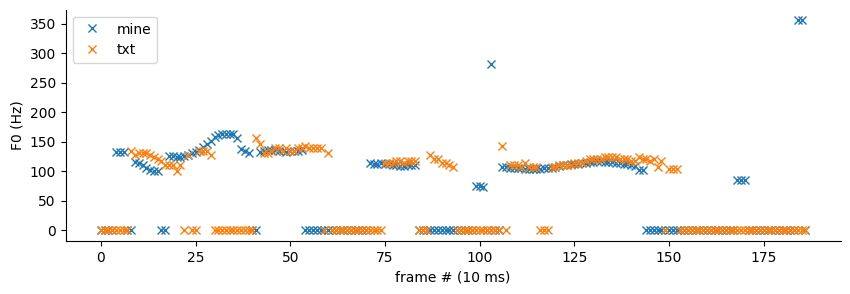

In [4]:
for d in data:
    x = d['rec']
    hop = int(0.01*fs)
    N = int(0.04*fs)
    
    lag_min = int(fs/350)
    lag_max = int(fs/40)

    xpad = np.concatenate([x, np.zeros(N+lag_max)])
    
    n_frames = int(np.ceil(len(x)/hop))
    my_f0 = np.zeros(n_frames) 
    for i in range(n_frames):
        part = xpad[i*hop:i*hop+N]
        part = part-part.mean()

        autocorr = np.zeros(lag_max+1)
        for lag in range(lag_max+1):
            autocorr[lag] = np.dot(part[:N-lag], part[lag:])
            
        autocorr = autocorr/(autocorr[0]+0.000000000001) 
        best_lag = lag_min+np.argmax(autocorr[lag_min:lag_max+1])

        if autocorr[best_lag] > 0.5:
            my_f0[i] = fs/best_lag

    d['my_f0'] = my_f0

    # check
    n = min(len(my_f0), len(d['f0']))
    est = my_f0[:n]
    ref = d['f0'][:n]

    agree = np.mean((est > 0) == (ref > 0))
    print(f"{d['idx']}: {agree}")

test_idx = 4
plt.figure(figsize=(10, 3))
plt.plot(data[test_idx]['my_f0'], 'x', label='mine')
plt.plot(data[test_idx]['f0'], 'x', label='txt')
plt.xlabel('frame # (10 ms)')
plt.ylabel('F0 (Hz)')
plt.legend()
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

# encoder + decoder

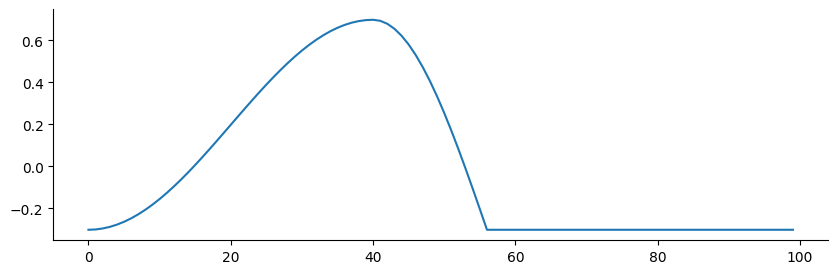

In [5]:
# glottal pulse check
period = 100
n = np.arange(int(period))
OPEN = 0.4*period 
SHUT = 0.16*period
pulse = np.zeros(int(period))
pulse[n < OPEN] = 0.5*(1-np.cos(np.pi*n[n < OPEN]/OPEN))
closing = (n >= OPEN) & (n < OPEN+SHUT)
pulse[closing] = np.cos(np.pi*(n[closing]-OPEN)/(2*SHUT))
pulse = pulse-pulse.mean()

fig = plt.figure(figsize=(10, 3))
plt.plot(pulse)
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

In [6]:
def lpc_vocoder(rec, fs, f0, order=16, frame_ms=20, shape='glottal', res_bits=0):
    L = int(frame_ms*fs/1000) 
    n_frames = int(np.ceil(len(rec)/L))
    xpad = np.concatenate([np.zeros(L), rec, np.zeros(2*L)]) 

    # encoder
    all_coeffs = []
    all_G = []
    all_f0 = []
    all_res = []
    
    for i in range(n_frames):
        start = L+(i*L)
        window = xpad[start-L//2:start+L+L //2] 
        lpc_coeffs, _ = lpc(window*np.hamming(len(window)), order)

        # residual
        seg = xpad[start-order:start+L] 
        res = np.zeros(L)
        for n in range(L):
            res[n] = np.dot(lpc_coeffs, seg[n:n+order+1][::-1])
        G = np.sqrt(np.mean(res**2))+0.000000001

        # pitch  - im using middle part
        track_idx = min(int((i+0.5)*frame_ms/10), len(f0)-1)

        all_coeffs.append(lpc_coeffs)
        all_G.append(G)
        all_f0.append(f0[track_idx])
        all_res.append(res)

    # decoder
    exc = np.zeros(n_frames*L+fs) 
    pos = 0 
    for i in range(n_frames):
        start = i*L
        G = all_G[i]

        if res_bits > 0:
            levels = 2**res_bits
            step = 6/levels
            q = np.clip(np.floor((all_res[i]/G+3)/step), 0, levels-1)
            exc[start:start+L] = (-3+(q+0.5)*step)*G
        elif all_f0[i] > 0:
            period = fs/all_f0[i] 
            if shape == 'glottal':
                # glottal pulse making
                n = np.arange(int(period))
                OPEN = 0.4*period 
                SHUT = 0.16*period
                pulse = np.zeros(int(period))
                pulse[n < OPEN] = 0.5*(1-np.cos(np.pi*n[n < OPEN]/OPEN))
                closing = (n >= OPEN) & (n < OPEN+SHUT)
                pulse[closing] = np.cos(np.pi*(n[closing]-OPEN)/(2*SHUT))
                pulse = pulse-pulse.mean()
            else:
                pulse = np.array([1.0])
            pulse = pulse*np.sqrt(period/np.sum(pulse**2))*G  

            # voicing logic
            # basically if the last frame was unvoiced, start the pulse train at this frame
            if pos < start:
                pos = start
            while pos < start+L:
                exc[int(pos):int(pos)+len(pulse)] += pulse
                pos = pos+period
        else:
            exc[start:start+L] += np.random.randn(L)*G  

    # 1/A(z)
    # y[n] = e[n] - sum_{k>=1} a[k]*y[n-k]
    synth = np.zeros(order+n_frames*L) 
    for i in range(n_frames):
        lpc_coeffs = all_coeffs[i]
        for n in range(i*L, (i+1)*L):
            m = n+order
            synth[m] = exc[n]-np.dot(lpc_coeffs[1:], synth[m-order:m][::-1])
    synth = synth[order:order+len(rec)]

    # per second send: order coefficients + G + pitch, per frame
    params_per_s = (order+2)*1000/frame_ms
    if res_bits > 0:
        params_per_s = (order+1)*1000/frame_ms+fs  # coefficients + G per frame, plus every residual sample
    return synth, params_per_s

params/s: 900.0, PESQ:1.343674898147583


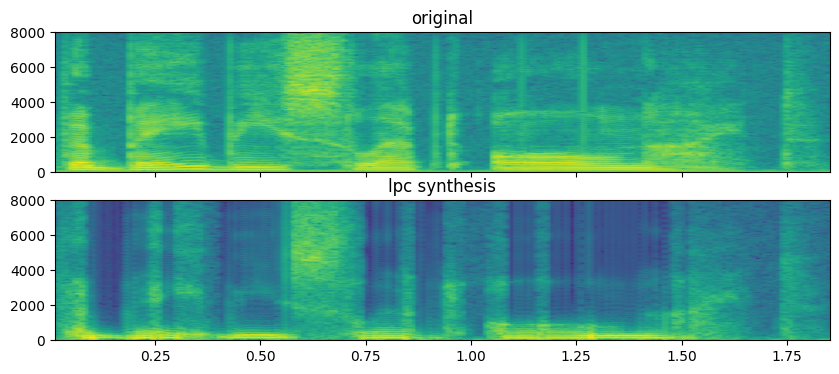

In [7]:
# SAMPLE TEST
from pesq import pesq
from IPython.display import Audio, display
import scipy.signal as sps

test= data[4]
synth, params_per_s = lpc_vocoder(test['rec'], fs, test['f0'])

x8 = sps.resample_poly(test['rec'], 8000, fs)
y8 = sps.resample_poly(synth, 8000, fs)
print(f'params/s: {params_per_s}, PESQ:{pesq(8000, x8, y8, "nb")}')

display(Audio(test['rec'], rate=fs), Audio(synth, rate=fs))

fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].specgram(test['rec'], Fs=test['fs'], NFFT=512, noverlap=384)
ax[0].set_title('original')
ax[1].specgram(synth, Fs=fs, NFFT=512, noverlap=384)
ax[1].set_title('lpc synthesis')
plt.show()

# experiments
optimal parameters

frame 5 ms, order 8: 2000 params/s, PESQ 1.29
frame 5 ms, order 12: 2800 params/s, PESQ 1.34
frame 5 ms, order 16: 3600 params/s, PESQ 1.38
frame 5 ms, order 32: 6800 params/s, PESQ 1.38
frame 10 ms, order 8: 1000 params/s, PESQ 1.29
frame 10 ms, order 12: 1400 params/s, PESQ 1.31
frame 10 ms, order 16: 1800 params/s, PESQ 1.36
frame 10 ms, order 32: 3400 params/s, PESQ 1.39
frame 20 ms, order 8: 500 params/s, PESQ 1.27
frame 20 ms, order 12: 700 params/s, PESQ 1.30
frame 20 ms, order 16: 900 params/s, PESQ 1.34
frame 20 ms, order 32: 1700 params/s, PESQ 1.36
frame 30 ms, order 8: 333 params/s, PESQ 1.23
frame 30 ms, order 12: 467 params/s, PESQ 1.26
frame 30 ms, order 16: 600 params/s, PESQ 1.31
frame 30 ms, order 32: 1133 params/s, PESQ 1.32


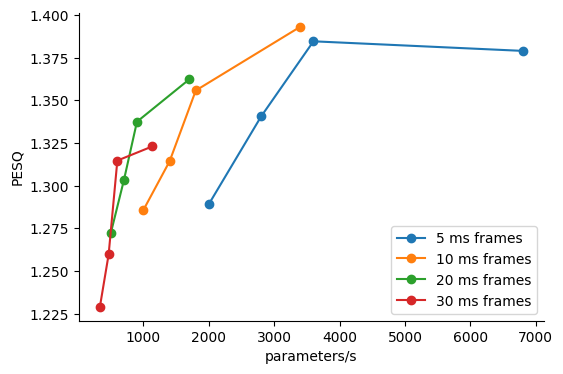

In [8]:
# frame length and order vs quality (compression rate vs quality)
results = []
for frame_ms in [5, 10, 20, 30]:
    for order in [8, 12, 16, 32]:
        scores = []
        for d in data:
            synth, params_per_s = lpc_vocoder(d['rec'], d['fs'], d['f0'], order=order, frame_ms=frame_ms)
            x8 = sps.resample_poly(d['rec'], 8000, d['fs'])
            y8 = sps.resample_poly(synth, 8000, d['fs'])
            scores.append(pesq(8000, x8, y8, 'nb'))
        results.append([frame_ms, order, params_per_s, np.mean(scores)])
        print(f'frame {frame_ms} ms, order {order}: {params_per_s:.0f} params/s, PESQ {np.mean(scores):.2f}')

results = np.array(results)
plt.figure(figsize=(6, 4))
for frame_ms in [5, 10, 20, 30]:
    rows = results[results[:, 0] == frame_ms]
    plt.plot(rows[:, 2], rows[:, 3], 'o-', label=f'{frame_ms} ms frames')
plt.xlabel('parameters/s')
plt.ylabel('PESQ')
plt.legend()
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

In [9]:
# 20 ms order 32 seems good balance
# best was 10 ms, order 32 for pesq
# best was 30 ms, order 16 for lowest rate

impulse, frame 30 ms, order 16: 600 params/s, PESQ 1.71
impulse, frame 20 ms, order 32: 1700 params/s, PESQ 1.93
impulse, frame 10 ms, order 32: 3400 params/s, PESQ 2.11
rosenberg, frame 30 ms, order 16: 600 params/s, PESQ 1.70
rosenberg, frame 20 ms, order 32: 1700 params/s, PESQ 1.94
rosenberg, frame 10 ms, order 32: 3400 params/s, PESQ 2.07


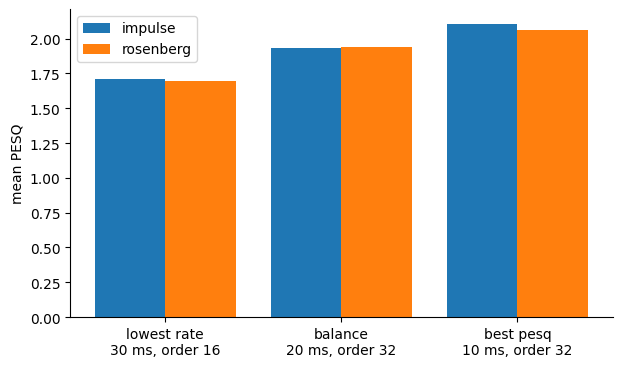

In [10]:
# glottal shape across those settings
settings = [(30, 16, 'lowest rate'), (20, 32, 'balance'), (10, 32, 'best pesq')]
shapes = ['impulse', 'rosenberg']

all_scores = np.zeros((len(shapes), len(settings)))
for s, shape in enumerate(shapes):
    for c, (frame_ms, order, label) in enumerate(settings):
        scores = []
        for d in data:
            synth, params_per_s = lpc_vocoder(d['rec'], fs, d['f0'], order=order, frame_ms=frame_ms, shape=shape)
            n8 = int(len(d['rec'])*8000/fs)
            x8 = sps.resample_poly(d['rec'], 8000, fs)
            y8 = sps.resample_poly(synth, 8000, fs)
            scores.append(pesq(8000, x8, y8, 'nb'))
        all_scores[s, c] = np.mean(scores)
        print(f'{shape}, frame {frame_ms} ms, order {order}: {params_per_s:.0f} params/s, PESQ {np.mean(scores):.2f}')

x = np.arange(len(settings))
plt.figure(figsize=(7, 4))
plt.bar(x-0.2, all_scores[0], 0.4, label='impulse')
plt.bar(x+0.2, all_scores[1], 0.4, label='rosenberg')
plt.xticks(x, [f'{label}\n{frame_ms} ms, order {order}' for frame_ms, order, label in settings])
plt.ylabel('mean PESQ')
plt.legend()
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

voicing txt, frame 30 ms, order 16: PESQ 1.30
voicing txt, frame 20 ms, order 32: PESQ 1.36
voicing txt, frame 10 ms, order 32: PESQ 1.39
voicing mine, frame 30 ms, order 16: PESQ 1.49
voicing mine, frame 20 ms, order 32: PESQ 1.50
voicing mine, frame 10 ms, order 32: PESQ 1.59
voicing none, frame 30 ms, order 16: PESQ 1.60
voicing none, frame 20 ms, order 32: PESQ 1.81
voicing none, frame 10 ms, order 32: PESQ 1.87


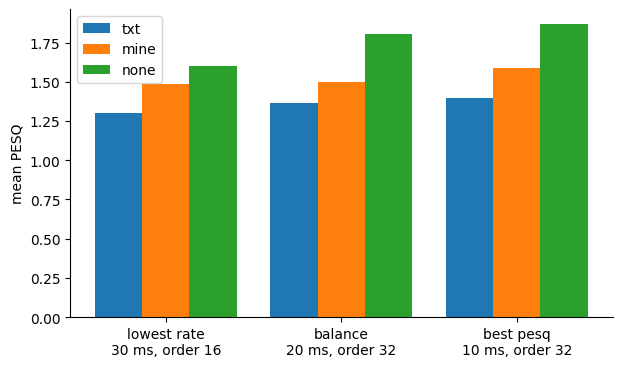

In [11]:
# voicing
settings = [(30, 16, 'lowest rate'), (20, 32, 'balance'), (10, 32, 'best pesq')]
sources = ['txt', 'mine', 'none']

all_scores = np.zeros((len(sources), len(settings)))
for s, name in enumerate(sources):
    for c, (frame_ms, order, label) in enumerate(settings):
        scores = []
        for d in data:
            if name == 'txt':
                f0 = d['f0']
            elif name == 'mine':
                f0 = d['my_f0']
            else:
                f0 = np.zeros(len(d['f0']))
            synth, params_per_s = lpc_vocoder(d['rec'], d['fs'], f0, order=order, frame_ms=frame_ms)
            x8 = sps.resample_poly(d['rec'], 8000, d['fs'])
            y8 = sps.resample_poly(synth, 8000, d['fs'])
            scores.append(pesq(8000, x8, y8, 'nb'))
        all_scores[s, c] = np.mean(scores)
        print(f'voicing {name}, frame {frame_ms} ms, order {order}: PESQ {np.mean(scores):.2f}')

x = np.arange(len(settings))
plt.figure(figsize=(7, 4))
plt.bar(x-0.27, all_scores[0], 0.27, label='txt')
plt.bar(x, all_scores[1], 0.27, label='mine')
plt.bar(x+0.27, all_scores[2], 0.27, label='none')
plt.xticks(x, [f'{label}\n{frame_ms} ms, order {order}' for frame_ms, order, label in settings])
plt.ylabel('mean PESQ')
plt.legend()
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

In [12]:
# save all 10 using 
# my voicing, impulse shape, 20 ms order 32

for d in data:
    synth, params_per_s = lpc_vocoder(d['rec'], fs, d['my_f0'], order=32, frame_ms=20, shape='impulse')
    sf.write(f'synth/{d["idx"]}_synth.wav', synth/np.max(np.abs(synth)), d['fs'])

In [13]:
# sremaining error - adds res_bits*fs bits/s
for res_bits in [1, 2, 3]:
    scores = []
    for d in data:
        synth, params_per_s = lpc_vocoder(d['rec'], d['fs'], d['f0'], res_bits=res_bits)
        x8 = sps.resample_poly(d['rec'], 8000, d['fs'])
        y8 = sps.resample_poly(synth, 8000, d['fs'])
        scores.append(pesq(8000, x8, y8, 'nb'))
    print(f'res {res_bits} bits/sample: +{res_bits*data[0]["fs"]} bits/s, PESQ {np.mean(scores):.2f}')

res 1 bits/sample: +16000 bits/s, PESQ 2.67
res 2 bits/sample: +32000 bits/s, PESQ 3.35
res 3 bits/sample: +48000 bits/s, PESQ 3.93


# my recording

In [14]:
rec, fs = sf.read(r'C:\Users\catra\OneDrive\Documents\Repos\lpc-vocoder\my_rec.wav')
rec = rec.mean(axis=1) 
fs

48000

In [15]:
# resample since its diff than 16 kHz
rec = sps.resample_poly(rec, 16000, fs)
fs = 16000
rec = rec/np.max(np.abs(rec)) 

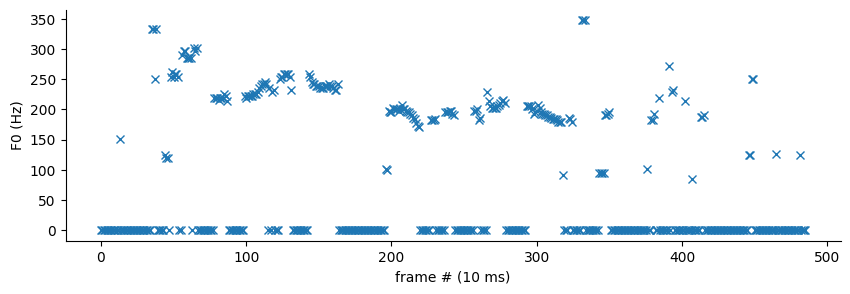

In [16]:
# my voicing (same as the voicing part) --> copying frome arlier
hop = int(0.01*fs)
N = int(0.04*fs)

lag_min = int(fs/350)
lag_max = int(fs/40)

xpad = np.concatenate([rec, np.zeros(N+lag_max)])

n_frames = int(np.ceil(len(rec)/hop))
my_f0 = np.zeros(n_frames) 
for i in range(n_frames):
    part = xpad[i*hop:i*hop+N]
    part = part-part.mean()

    autocorr = np.zeros(lag_max+1)
    for lag in range(lag_max+1):
        autocorr[lag] = np.dot(part[:N-lag], part[lag:])
        
    autocorr = autocorr/(autocorr[0]+0.000000000001) 
    best_lag = lag_min+np.argmax(autocorr[lag_min:lag_max+1])

    if autocorr[best_lag] > 0.5:
        my_f0[i] = fs/best_lag

plt.figure(figsize=(10, 3))
plt.plot(my_f0, 'x')
plt.xlabel('frame # (10 ms)')
plt.ylabel('F0 (Hz)')
gca = plt.gca()
gca.spines['top'].set_visible(False)
gca.spines['right'].set_visible(False)
plt.show()

In [19]:
best_score = 0
for frame_ms in [10, 15, 20, 30]:
    for order in [8, 16, 32, 64]:
        synth, params_per_s = lpc_vocoder(rec, fs, my_f0, order=order, frame_ms=frame_ms)

        x8 = sps.resample_poly(rec, 8000, fs)
        y8 = sps.resample_poly(synth, 8000, fs)
        score = pesq(8000, x8, y8, 'nb')
        print(f'frame {frame_ms} ms, order {order}: {params_per_s:.0f} params/s, PESQ {score:.2f}')
        if score > best_score:
            best_score = score
            best_synth = synth
            best_setting = (frame_ms, order)

print('best:', best_setting, f'PESQ {best_score}')
display(Audio(rec, rate=fs), Audio(best_synth, rate=fs))

sf.write(f'synth/my_rec_synth.wav', best_synth/np.max(np.abs(best_synth)), fs)

frame 10 ms, order 8: 1000 params/s, PESQ 1.51
frame 10 ms, order 16: 1800 params/s, PESQ 1.80
frame 10 ms, order 32: 3400 params/s, PESQ 1.65
frame 10 ms, order 64: 6600 params/s, PESQ 1.79
frame 15 ms, order 8: 667 params/s, PESQ 1.53
frame 15 ms, order 16: 1200 params/s, PESQ 1.77
frame 15 ms, order 32: 2267 params/s, PESQ 1.62
frame 15 ms, order 64: 4400 params/s, PESQ 1.72
frame 20 ms, order 8: 500 params/s, PESQ 1.46
frame 20 ms, order 16: 900 params/s, PESQ 1.65
frame 20 ms, order 32: 1700 params/s, PESQ 1.56
frame 20 ms, order 64: 3300 params/s, PESQ 1.63
frame 30 ms, order 8: 333 params/s, PESQ 1.37
frame 30 ms, order 16: 600 params/s, PESQ 1.54
frame 30 ms, order 32: 1133 params/s, PESQ 1.34
frame 30 ms, order 64: 2200 params/s, PESQ 1.46
best: (10, 16) PESQ 1.7997145652770996
